In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

In [2]:
url='https://raw.githubusercontent.com/jbrownlee/Datasets/refs/heads/master/airline-passengers.csv'
dataset=pd.read_csv(url,header=0,parse_dates=['Month'],index_col='Month')

In [3]:
dataset.head()

,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


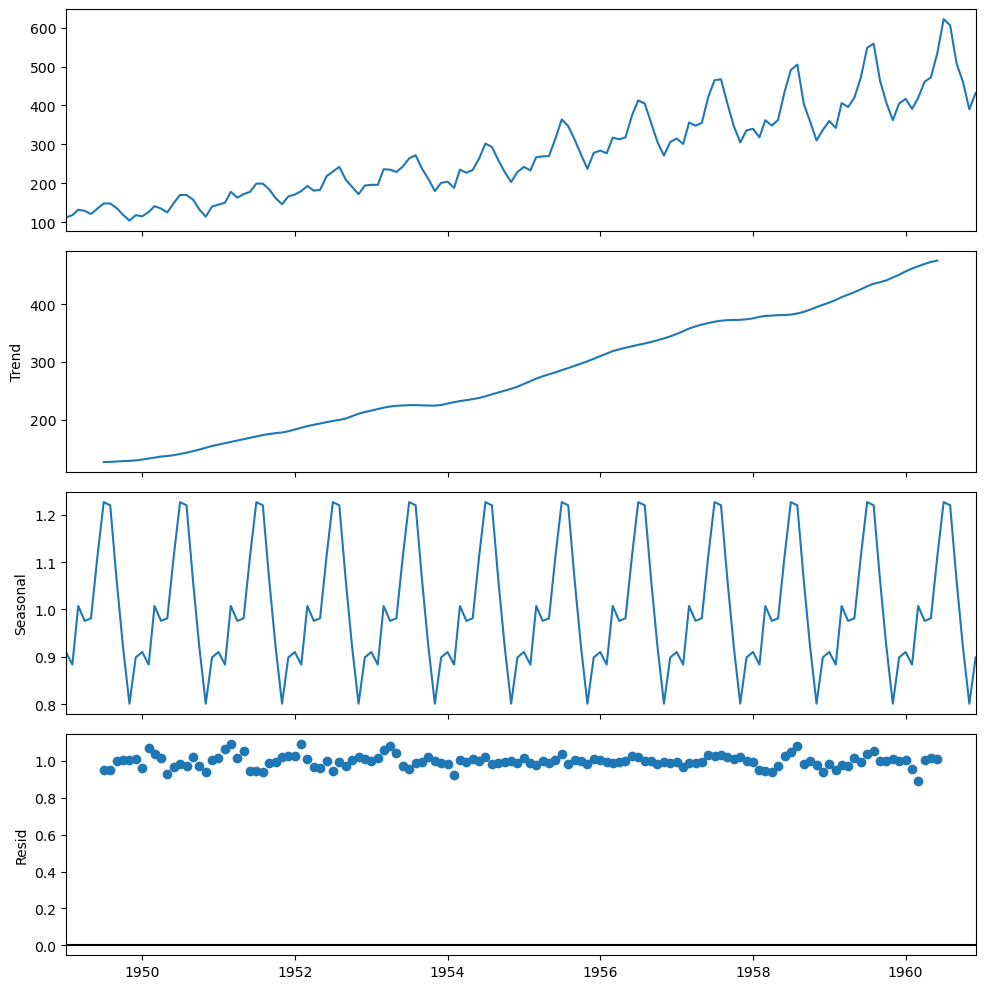

In [4]:
result=seasonal_decompose(dataset,model='multiplicative')
plt.rcParams.update({'figure.figsize':(10,10)})
result.plot()
plt.show()

In [5]:
ts=dataset['Passengers']
ts

Month
1949-01-01    112
1949-02-01    118
1949-03-01    132
1949-04-01    129
1949-05-01    121
             ... 
1960-08-01    606
1960-09-01    508
1960-10-01    461
1960-11-01    390
1960-12-01    432
Name: Passengers, Length: 144, dtype: int64

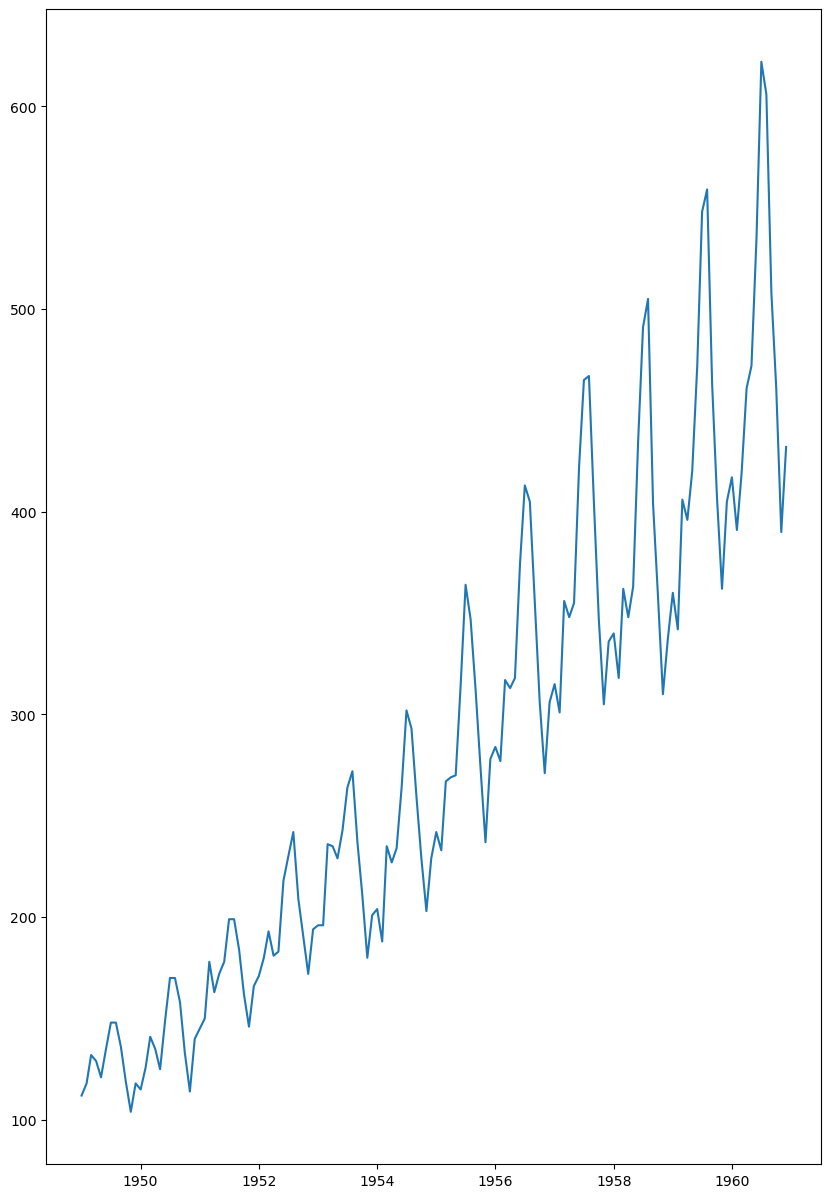

In [6]:
plt.figure(figsize=(10,15))
plt.plot(ts)

### Stationarity Test

In [7]:
from statsmodels.tsa.stattools import adfuller
def test_stationarity(timeseries):
    rolmean=pd.Series(timeseries).rolling(window=12).mean()
    rolstd=pd.Series(timeseries).rolling(window=12).std()
    plt.figure(figsize=(10,5))
    orig=plt.plot(timeseries,color='blue',label='Original')
    mean=plt.plot(rolmean,color='red',label='Rolling Mean')
    std=plt.plot(rolstd,color='black',label='Rolling Std')
    plt.legend(loc='best')
    plt.title('graphs')
    plt.show(block=False)

    dftest=adfuller(timeseries,autolag='AIC')
    print('P value',dftest[1])
    

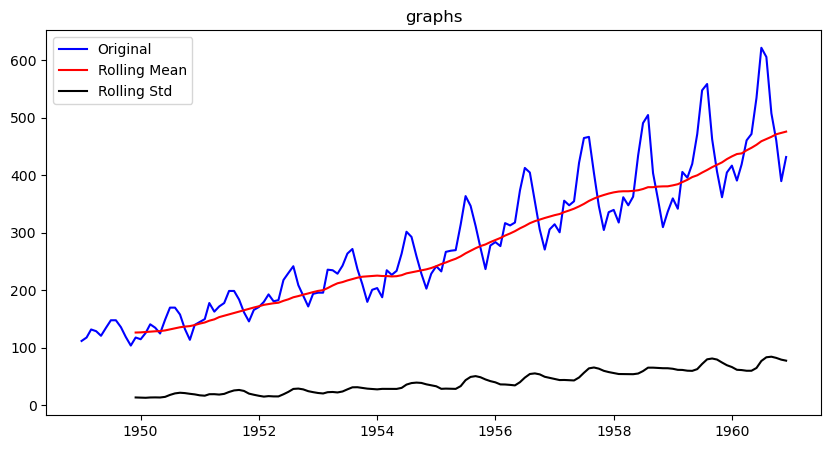

P value 0.9918802434376411


In [8]:
test_stationarity(ts)

## Transformation

In [9]:
ts_log=np.log(ts)

In [10]:
ts_log.head()

Month
1949-01-01    4.718499
1949-02-01    4.770685
1949-03-01    4.882802
1949-04-01    4.859812
1949-05-01    4.795791
Name: Passengers, dtype: float64

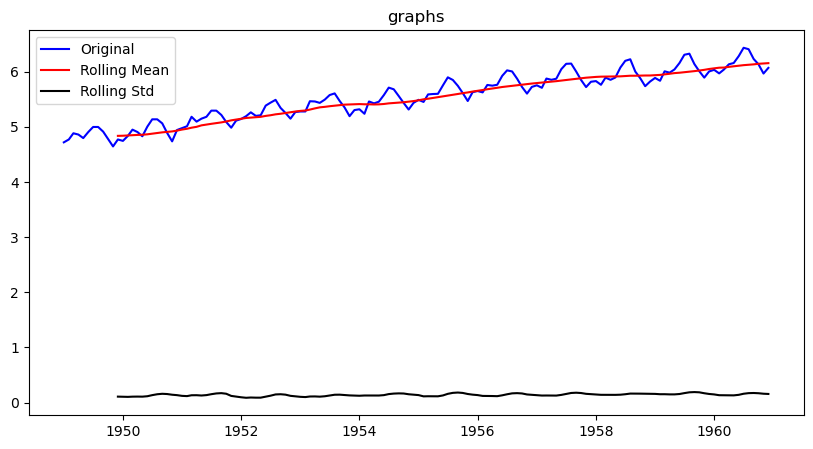

P value 0.4223667747703897


In [11]:
test_stationarity(ts_log)

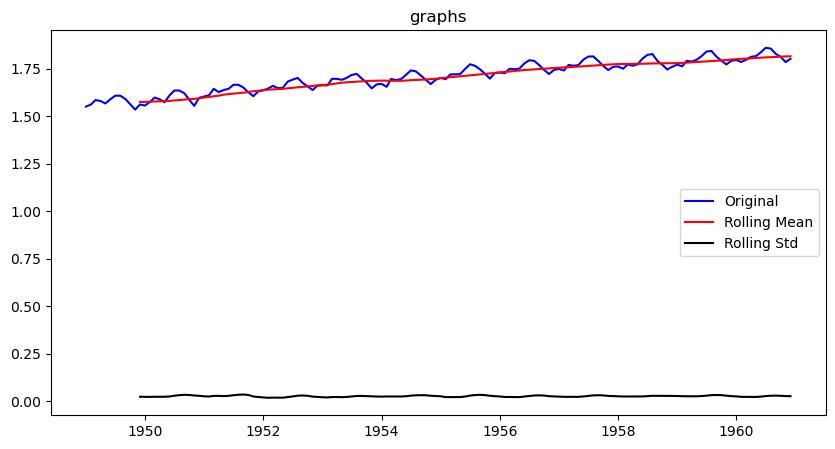

P value 0.2225898911706144


In [12]:
ts_double=np.log(ts_log)
test_stationarity(ts_double)

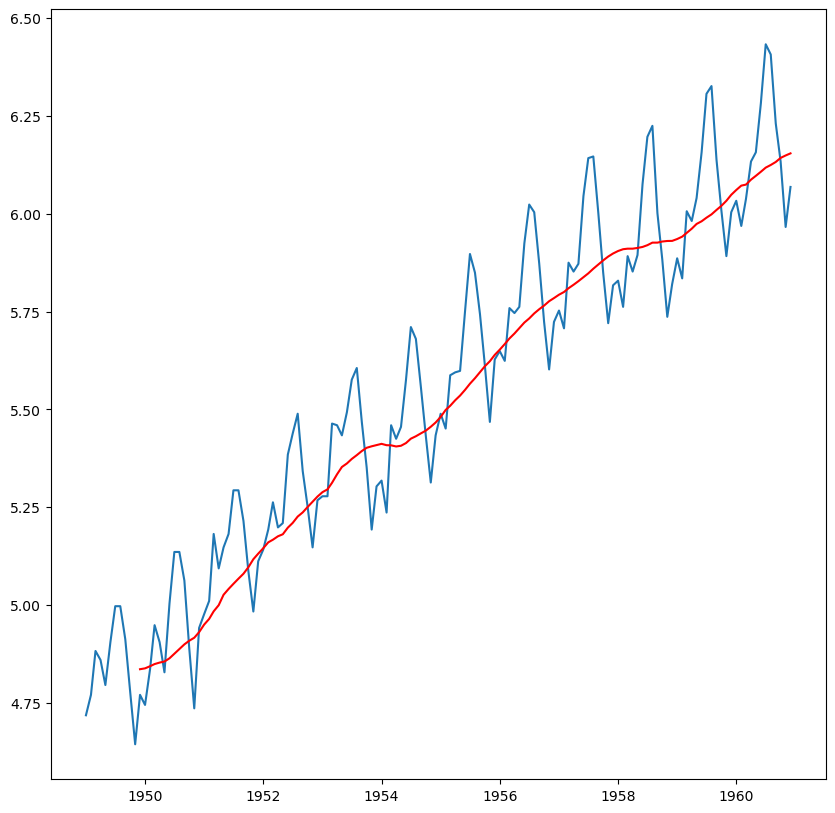

In [13]:
 #smoothing
moving_avg=pd.Series(ts_log).rolling(window=12).mean()
plt.plot(ts_log)
plt.plot(moving_avg,color='red')

ts_log_moving_avg_diff=ts_log-moving_avg
ts_log_moving_avg_diff.dropna(inplace=True)

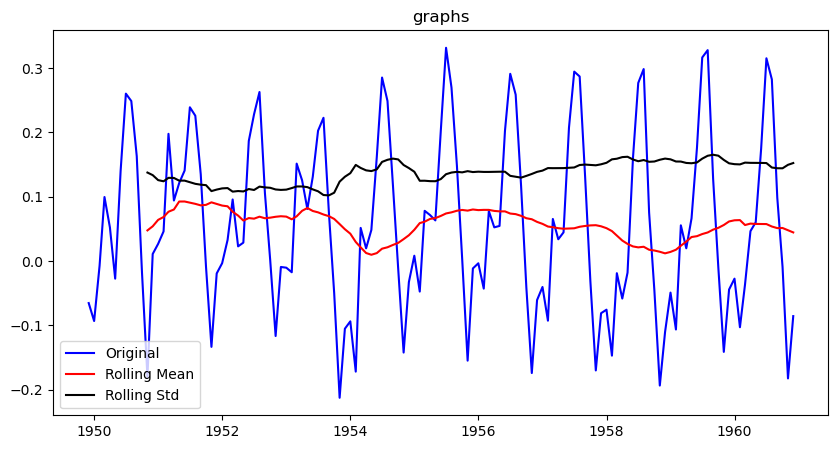

P value 0.02223463000124264


In [14]:
test_stationarity(ts_log_moving_avg_diff)

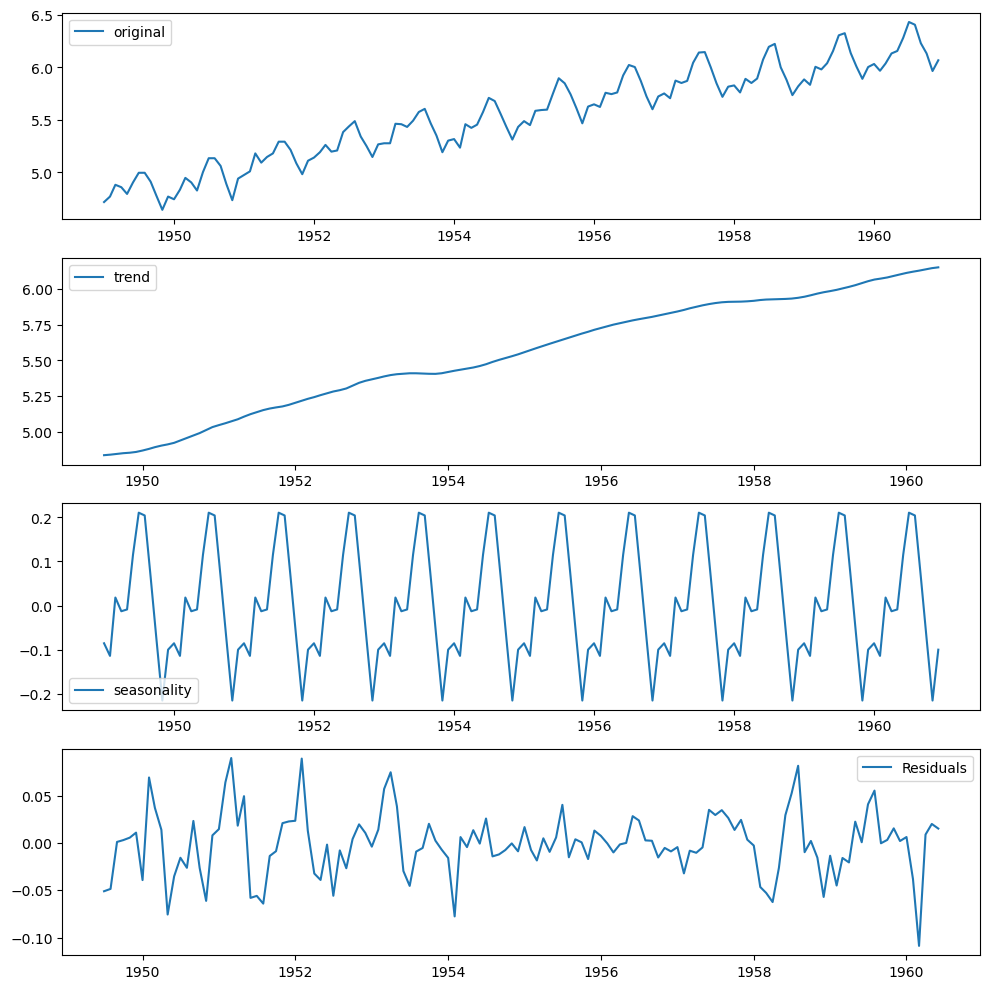

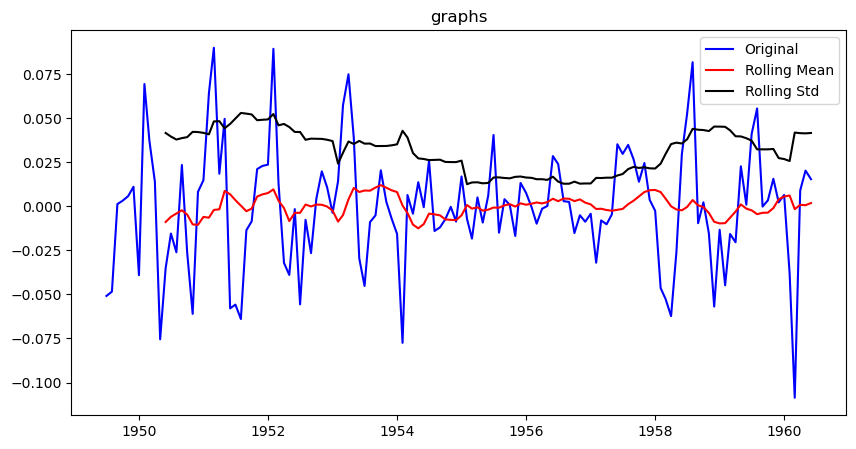

P value 2.885058903323395e-08


In [15]:
from statsmodels.tsa.seasonal import seasonal_decompose
decomposition=seasonal_decompose(ts_log)

trend=decomposition.trend
seasonal=decomposition.seasonal
residual=decomposition.resid

plt.subplot(411)
plt.plot(ts_log,label='original')
plt.legend(loc='best')
plt.subplot(412)
plt.plot(trend,label='trend')
plt.legend(loc='best')
plt.subplot(413)
plt.plot(seasonal,label='seasonality')
plt.legend(loc='best')
plt.subplot(414)
plt.plot(residual,label='Residuals')
plt.legend(loc='best')

plt.tight_layout()
plt.show()

ts_log_decompose=residual
ts_log_decompose.dropna(inplace=True)
test_stationarity(ts_log_decompose)